#### Overlapping Mitigation

Using TomeKLinks, SmoteTomek, ClusterCentroids

In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

df = pd.read_csv("../HeartDisease_cleaned.csv")
df

,Age,Sex,RestingBP,Cholesterol,FastingBS,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease,ChestPainType_ASY,ChestPainType_ATA,ChestPainType_NAP,ChestPainType_TA,RestingECG_LVH,RestingECG_Normal,RestingECG_ST
0,40,1,140,289,0,172,0,0.0,3,0,0,1,0,0,0,1,0
1,49,0,160,180,0,156,0,1.0,2,1,0,0,1,0,0,1,0
2,37,1,130,283,0,98,0,0.0,3,0,0,1,0,0,0,0,1
3,48,0,138,214,0,108,1,1.5,2,1,1,0,0,0,0,1,0
4,54,1,150,195,0,122,0,0.0,3,0,0,0,1,0,0,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
913,45,1,110,264,0,132,0,1.2,2,1,0,0,0,1,0,1,0
914,68,1,144,193,1,141,0,3.4,2,1,1,0,0,0,0,1,0
915,57,1,130,131,0,115,1,1.2,2,1,1,0,0,0,0,1,0
916,57,0,130,236,0,174,0,0.0,2,1,0,1,0,0,1,0,0


In [2]:
df.head()

,Age,Sex,RestingBP,Cholesterol,FastingBS,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease,ChestPainType_ASY,ChestPainType_ATA,ChestPainType_NAP,ChestPainType_TA,RestingECG_LVH,RestingECG_Normal,RestingECG_ST
0,40,1,140,289,0,172,0,0.0,3,0,0,1,0,0,0,1,0
1,49,0,160,180,0,156,0,1.0,2,1,0,0,1,0,0,1,0
2,37,1,130,283,0,98,0,0.0,3,0,0,1,0,0,0,0,1
3,48,0,138,214,0,108,1,1.5,2,1,1,0,0,0,0,1,0
4,54,1,150,195,0,122,0,0.0,3,0,0,0,1,0,0,1,0


<Axes: xlabel='Age', ylabel='MaxHR'>

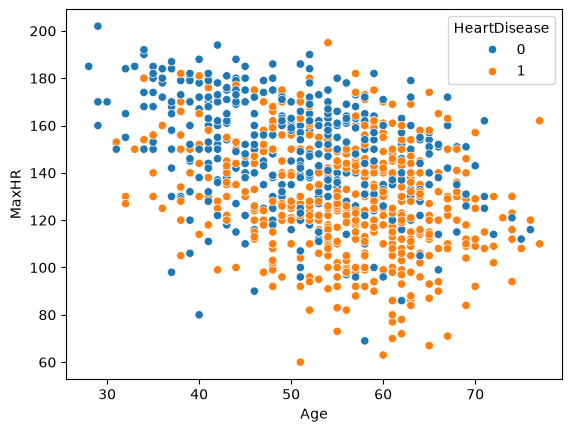

In [4]:
# Now let's take a particularly nasty overlap. Here.
sns.scatterplot(df, x="Age", y="MaxHR", hue="HeartDisease")

# In real life, does this overlap seem feasible? Probably.
# There's always some overlap (especially in health diagnosis data).




#### TomeKLinks

In [7]:
from imblearn.under_sampling import TomekLinks

df = df.dropna()

# X y split to prevent data leakage
X = df.drop(columns="HeartDisease", axis=1)
y = df["HeartDisease"]

# Let's use vanilla tomeklinks
tomek = TomekLinks()

# Fit and resample.
X_resampled, y_resampled = tomek.fit_resample(X, y)

# Make a new copy (so we don't have trouble with dependency)
df_resampled = X_resampled.copy()

# Add y back into the X rows
df_resampled["HeartDisease"] = y_resampled
df_resampled

,Age,Sex,RestingBP,Cholesterol,FastingBS,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,ChestPainType_ASY,ChestPainType_ATA,ChestPainType_NAP,ChestPainType_TA,RestingECG_LVH,RestingECG_Normal,RestingECG_ST,HeartDisease
0,40,1,140,289,0,172,0,0.0,3,0,1,0,0,0,1,0,0
1,37,1,130,283,0,98,0,0.0,3,0,1,0,0,0,0,1,0
2,48,0,138,214,0,108,1,1.5,2,1,0,0,0,0,1,0,1
3,54,1,150,195,0,122,0,0.0,3,0,0,1,0,0,1,0,0
4,39,1,120,339,0,170,0,0.0,3,0,0,1,0,0,1,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
840,45,1,110,264,0,132,0,1.2,2,0,0,0,1,0,1,0,1
841,68,1,144,193,1,141,0,3.4,2,1,0,0,0,0,1,0,1
842,57,1,130,131,0,115,1,1.2,2,1,0,0,0,0,1,0,1
843,57,0,130,236,0,174,0,0.0,2,0,1,0,0,1,0,0,1


In [8]:
df.columns

Index(['Age', 'Sex', 'RestingBP', 'Cholesterol', 'FastingBS', 'MaxHR',
       'ExerciseAngina', 'Oldpeak', 'ST_Slope', 'HeartDisease',
       'ChestPainType_ASY', 'ChestPainType_ATA', 'ChestPainType_NAP',
       'ChestPainType_TA', 'RestingECG_LVH', 'RestingECG_Normal',
       'RestingECG_ST'],
      dtype='object')

<Axes: xlabel='Age', ylabel='MaxHR'>

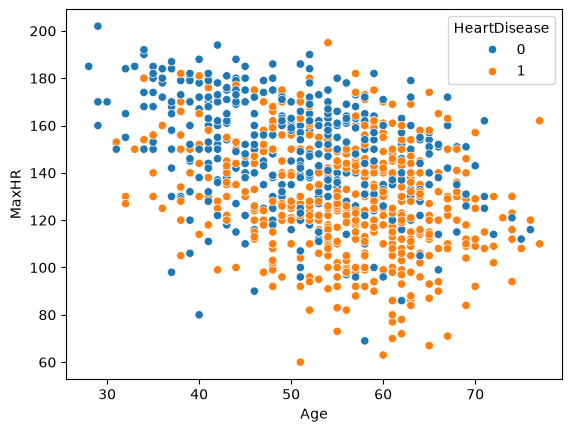

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt
# The current problem is that our dataset has overlap between the classes
# that could affect our ML models. Take a look.
sns.scatterplot(df, x="Age", y="MaxHR", hue="HeartDisease")

# In real life, does this overlap seem feasible? Probably.
# There's always some overlap (especially in health diagnosis data).

# But say this didn't reflect reality and there's some reason to
# fix the overlap...

In [ ]:
from imblearn.under_sampling import ClusterCentroids

# X y split to prevent data leakage
X = df.drop(columns="HeartDisease", axis=1)
y = df["HeartDisease"]

strategy = {
  
    1: 410
}

cc = ClusterCentroids(
    sampling_strategy=strategy,
    # random_state=31555
)

X_resampled, y_resampled = cc.fit_resample(X, y)

# Make a new copy (so we don't have trouble with dependency)
df_resampled = X_resampled.copy()

# Add y back into the X rows
df_resampled["HeartDisease"] = y_resampled
df_resampled

,Age,Sex,RestingBP,Cholesterol,FastingBS,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,ChestPainType_ASY,ChestPainType_ATA,ChestPainType_NAP,ChestPainType_TA,RestingECG_LVH,RestingECG_Normal,RestingECG_ST,HeartDisease
0,40,1,140,289,0,172,0,0.00,3,0,1,0,0,0,1,0,0
1,37,1,130,283,0,98,0,0.00,3,0,1,0,0,0,0,1,0
2,54,1,150,195,0,122,0,0.00,3,0,0,1,0,0,1,0,0
3,39,1,120,339,0,170,0,0.00,3,0,0,1,0,0,1,0,0
4,45,0,130,237,0,170,0,0.00,3,0,1,0,0,0,1,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
815,50,1,144,200,0,126,1,0.90,2,1,0,0,0,1,0,0,1
816,65,1,160,0,1,122,0,1.20,2,1,0,0,0,0,0,1,1
817,51,1,140,298,0,122,1,4.20,2,1,0,0,0,0,1,0,1
818,43,1,115,0,0,145,1,2.00,2,1,0,0,0,0,1,0,1


Text(0.5, 1.0, 'Original')

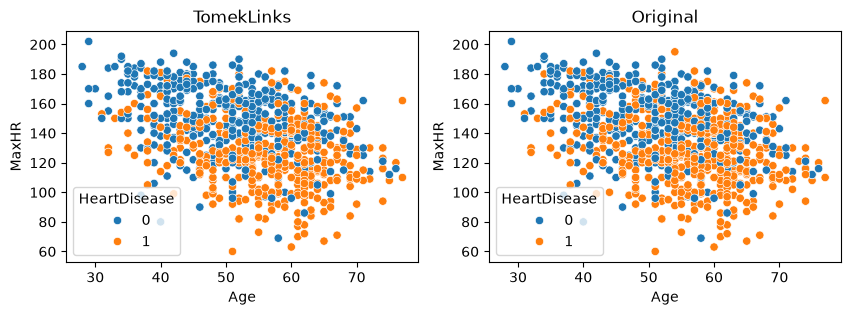

In [9]:
# Let's look at it again. How did it perform?
fig, axes = plt.subplots(1, 2, figsize=(10, 3))
sns.scatterplot(df_resampled, x="Age", y="MaxHR", hue="HeartDisease", ax=axes[0])
sns.scatterplot(df, x="Age", y="MaxHR", hue="HeartDisease", ax=axes[1]) 

axes[0].set_title("TomekLinks")
axes[1].set_title("Original")

# Quite underwhelming... That sort of makes sense though. Tomek is notoriously 
# conservative, even with large amounts of data. Hence why it's commonly used with SMOTE first.

In [ ]:
# But let's do a sanity check. How many rows did it get rid of?
print(df.shape)
print(df_resampled.shape)

(918, 17)
(820, 17)
